# Modeling

**Goal:** train and compare models that predict the energy use of non-residential buildings in Seattle, starting from the features built in `02_feature_engineering.ipynb`.

## 0. Setup

Imports and load the dataset with the engineered features.

`buildings_feature_engineered.parquet` is the output of `02_feature_engineering.ipynb`.

To generate it, run `notebooks/01_eda.ipynb` then `notebooks/02_feature_engineering.ipynb` from top to bottom. The file is written to `data/processed/buildings_feature_engineered.parquet`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

df = pd.read_parquet("../data/processed/buildings_feature_engineered.parquet")
print(f"Dataset: {df.shape[0]} rows x {df.shape[1]} columns")

Dataset: 1535 rows x 12 columns


## 1. Train/test split

The test set is set aside now and is only used once, for the final evaluation. Everything else (imputation, encoding, feature selection, hyperparameters) is fitted on the training set only, inside the cross-validation.

- **Split:** 80% train / 20% test, fixed `random_state` for reproducibility.
- **Target:** `SiteEnergyUse(kBtu)` is right-skewed, so it is modeled as `log10` (decision of notebook 1). `y` is kept in kBtu: the model will be wrapped in a `TransformedTargetRegressor` (`func=np.log10`), which fits on `log10(y)` and returns predictions in kBtu, so the metrics are computed in kBtu.
- **Stratification:**a continuous target cannot be stratified directly. The target is cut into 10 quantile bins (deciles; the bins are identical on `y` and on `log10(y)`, since the log is monotonic), and the split is stratified on these bins so that the training and test sets cover the whole range of consumption, including the few very large buildings. The bins are computed on the whole dataset, but they are only used to draw the split: they are not a feature and never reach the models.

The check below compares the `log10` target distributions of the two sets (the log is only computed for display).

In [2]:
TARGET = "SiteEnergyUse(kBtu)"
RANDOM_STATE = 42

X = df.drop(columns=TARGET)
y = df[TARGET]  # kBtu; the log10 transform is done by TransformedTargetRegressor

# Stratify on deciles of the target (the bins are the same on y and log10(y))
y_bins = pd.qcut(y, q=10, labels=False)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y_bins, random_state=RANDOM_STATE
)
print(f"Train: {len(X_train)} rows | Test: {len(X_test)} rows")

Train: 1228 rows | Test: 307 rows


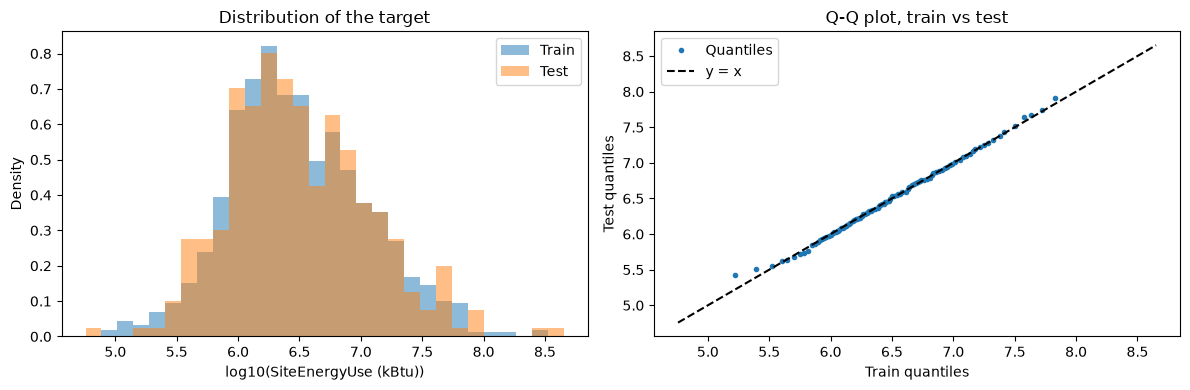

,Train,Test
count,1228.000,307.000
mean,6.492,6.498
std,0.564,0.577
min,4.902,4.757
25%,6.101,6.087
50%,6.437,6.429
75%,6.861,6.872
max,8.467,8.652


In [3]:
# Check: log10(y) distributions of the two sets (for display only)
log_train, log_test = np.log10(y_train), np.log10(y_test)
log_all = np.log10(y)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

bins = np.linspace(log_all.min(), log_all.max(), 31)
axes[0].hist(log_train, bins=bins, density=True, alpha=0.5, label="Train")
axes[0].hist(log_test, bins=bins, density=True, alpha=0.5, label="Test")
axes[0].set_xlabel("log10(SiteEnergyUse (kBtu))")
axes[0].set_ylabel("Density")
axes[0].set_title("Distribution of the target")
axes[0].legend()

quantiles = np.linspace(0.01, 0.99, 99)
axes[1].plot(
    log_train.quantile(quantiles), log_test.quantile(quantiles), ".", label="Quantiles"
)
axes[1].plot(
    [log_all.min(), log_all.max()], [log_all.min(), log_all.max()], "k--", label="y = x"
)
axes[1].set_xlabel("Train quantiles")
axes[1].set_ylabel("Test quantiles")
axes[1].set_title("Q-Q plot, train vs test")
axes[1].legend()

plt.tight_layout()
plt.show()

summary = pd.DataFrame({"Train": log_train.describe(), "Test": log_test.describe()})
display(summary.round(3))

In [4]:
counts = (
    pd.DataFrame(
        {
            "Train": X_train["PrimaryPropertyType"].value_counts(),
            "Test": X_test["PrimaryPropertyType"].value_counts(),
        }
    )
    .fillna(0)
    .astype(int)
)
counts["Test share"] = (counts["Test"] / (counts["Train"] + counts["Test"])).round(3)
counts.sort_values("Train", ascending=False)

,Train,Test,Test share
PrimaryPropertyType,,,
Small- and Mid-Sized Office,226,60,0.210
Other,197,48,0.196
Warehouse,147,38,0.205
Large Office,131,38,0.225
Mixed Use Property,80,24,0.231
Retail Store,73,12,0.141
Hotel,57,18,0.240
Worship Facility,56,13,0.188
Distribution Center,49,4,0.075


### Checks

- The stratification works. The two sets have almost the same mean (6.49 vs 6.50 in log10), median (6.44 vs 6.43) and spread, and the points of the Q-Q plot follow the diagonal over the whole range, including the largest consumers.
- The target is strictly positive (minimum of 4.76 in log10), so the log10 transform is always defined. The largest building of the test set (8.65) is above the maximum of the training set (8.47): the models will have to predict beyond the values they were trained on.
- Most property types have about 20% of their buildings in the test set. By chance, no hospital ends up in the test set. The split is kept as is: changing the random seed to fix this would mean choosing the test set after looking at it. The behavior of the models on hospitals is assessed through cross-validation instead, where each building is used once for validation.

## 2. Analysis of the target (training set only)

Everything in this section uses `X_train` and `y_train`. The test set is not looked at.

The exploration of notebooks 1 and 2 is not repeated. This section re-checks, on the training set, the relationships between the final features and the target, with a focus on the two weak signals (`ParkingShare`, `FloorAreaPerFloor`) and on the redundancy among the size variables.

As in notebook 2, the **intensity** (energy use divided by the building area) is used next to the target itself, because the building area dominates the total energy use and hides the other signals.

### Correlations with the target

Spearman rank correlations (insensitive to the skew, no need to log-transform).

In [5]:
train = X_train.assign(
    log_y=np.log10(y_train),
    log_intensity=np.log10(y_train / X_train["PropertyGFABuilding(s)"]),
)

numeric = [
    "PropertyGFABuilding(s)",
    "NumberofFloors",
    "NumberofBuildings",
    "FloorAreaPerFloor",
    "ParkingShare",
    "HasMixedUsage",
    "Latitude",
    "Longitude",
]
corr = pd.DataFrame(
    {
        "vs log10(y)": train[numeric].corrwith(train["log_y"], method="spearman"),
        "vs log10(intensity)": train[numeric].corrwith(
            train["log_intensity"], method="spearman"
        ),
    }
)
corr.round(2)

,vs log10(y),vs log10(intensity)
PropertyGFABuilding(s),0.71,0.11
NumberofFloors,0.47,0.16
NumberofBuildings,0.12,0.09
FloorAreaPerFloor,0.23,-0.08
ParkingShare,0.31,0.21
HasMixedUsage,0.10,0.04
Latitude,0.06,0.12
Longitude,-0.04,-0.02


The total energy use is mostly driven by the building area (Spearman 0.71 with `log10(y)`), which hides everything else. Against the intensity (energy use per unit of area), the picture changes:

- `ParkingShare` is the strongest of the engineered features (0.21 with the intensity, 0.31 with `log10(y)`, because parking is correlated with large buildings).
- `FloorAreaPerFloor` is weak and changes sign: +0.23 with `log10(y)` (wider buildings are larger) but -0.08 with the intensity.
- `HasMixedUsage` (0.04), `NumberofBuildings` (0.09) and `Longitude` (-0.02) are weak. `NumberofFloors` (0.16) and `Latitude` (0.12) are modest.
- A rank correlation only sees monotonic relationships. The construction period and the property type are categorical and not in this table; their relationships were studied in notebooks 1 and 2.

These are descriptive values on the training set. The real test of a feature is its contribution to the model, assessed later with cross-validation.

The property type is categorical, so it is not in this table: its relationship with the intensity is shown below.

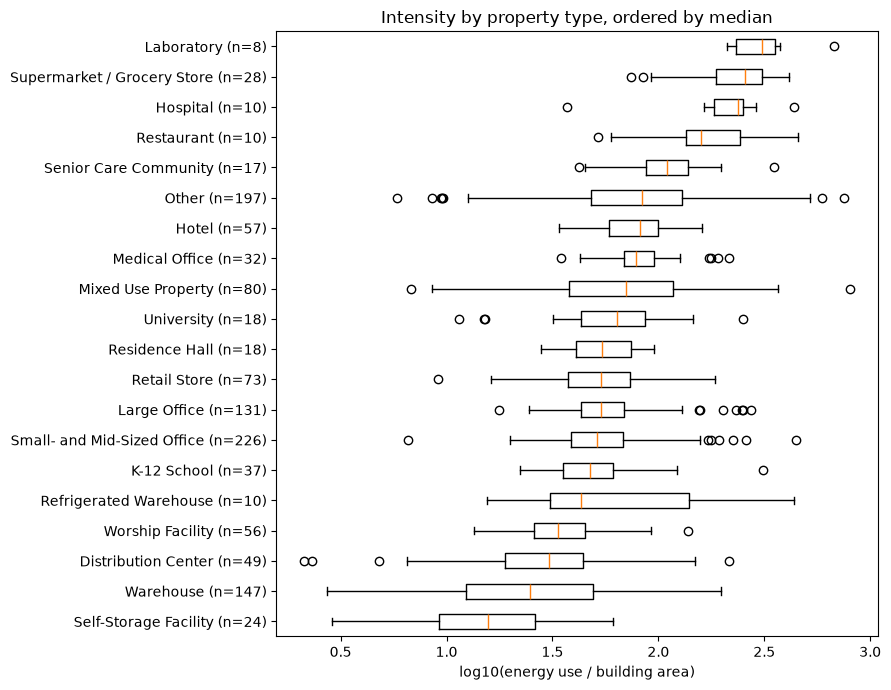

In [6]:
order = (
    train.groupby("PrimaryPropertyType")["log_intensity"].median().sort_values().index
)
groups = [train.loc[train["PrimaryPropertyType"] == t, "log_intensity"] for t in order]

fig, ax = plt.subplots(figsize=(9, 7))
ax.boxplot(
    groups,
    tick_labels=[f"{t} (n={len(g)})" for t, g in zip(order, groups)],
    orientation="horizontal",
)
ax.set_xlabel("log10(energy use / building area)")
ax.set_title("Intensity by property type, ordered by median")
plt.tight_layout()
plt.show()

The property type is the strongest driver of the energy use per unit of area. The median intensity ranges from about 1.2 (Self-Storage Facility) to about 2.5 (Laboratory) in log10: a laboratory uses about 20 times more energy per square foot than a self-storage facility. The order matches the business intuition: laboratories, supermarkets (refrigeration), hospitals (24/7 operation) and restaurants (cooking) are at the top, storage buildings at the bottom.

The spread inside each type varies a lot:
- Offices, the most frequent types (226 and 131 buildings), have narrow boxes: their intensity is homogeneous, so they should be well predicted.
- The catch-all categories (Other, Mixed Use Property) and Warehouse have wide boxes: they group buildings with very different actual uses. Other is the second most frequent type (197 buildings), so most prediction errors are expected there.
- The rarest types (8 to 10 buildings) are among the most extreme. Grouping rare categories at encoding time (`min_frequency`, `max_categories`) would merge laboratories, hospitals and refrigerated warehouses into a single column and lose the strongest signal of the dataset: all property types are therefore kept as separate categories.

### ParkingShare

Roughly one in five properties comes with pa arking. Two views: presence of a parking, and size of the parking among the properties that have one. Both are shown on the log10 intensity, to remove the effect of the building size.

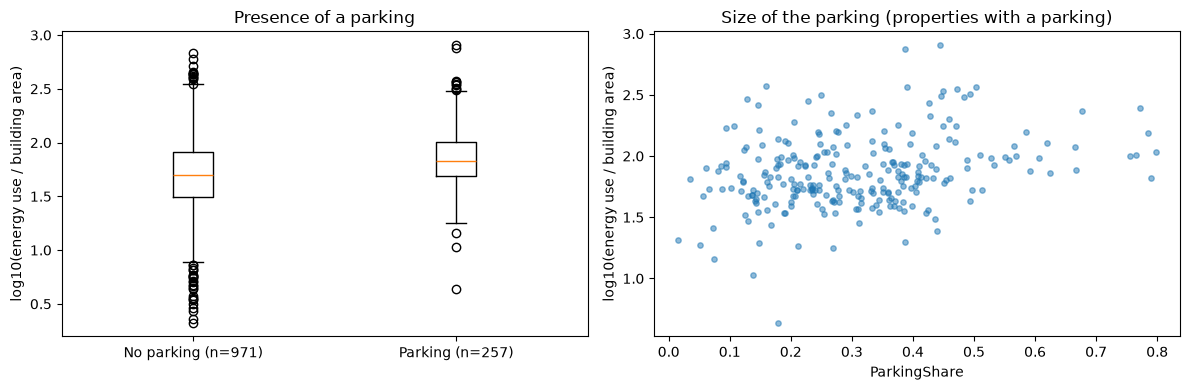

In [7]:
has_parking = train["ParkingShare"] > 0

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].boxplot(
    [train.loc[~has_parking, "log_intensity"], train.loc[has_parking, "log_intensity"]],
    tick_labels=[
        f"No parking (n={(~has_parking).sum()})",
        f"Parking (n={has_parking.sum()})",
    ],
)
axes[0].set_ylabel("log10(energy use / building area)")
axes[0].set_title("Presence of a parking")

axes[1].scatter(
    train.loc[has_parking, "ParkingShare"],
    train.loc[has_parking, "log_intensity"],
    s=15,
    alpha=0.5,
)
axes[1].set_xlabel("ParkingShare")
axes[1].set_ylabel("log10(energy use / building area)")
axes[1].set_title("Size of the parking (properties with a parking)")

plt.tight_layout()
plt.show()

Properties with a parking use more energy per unit of area: the median intensity is about 34% higher. Among them, intensity increases with the parking share, but with a lot of dispersion. This matches the hypothesis and the decision of notebook 2.

### FloorAreaPerFloor

Same quartiles as in notebook 2, recomputed on the training set (properties with a missing value, mostly campuses, are left out).

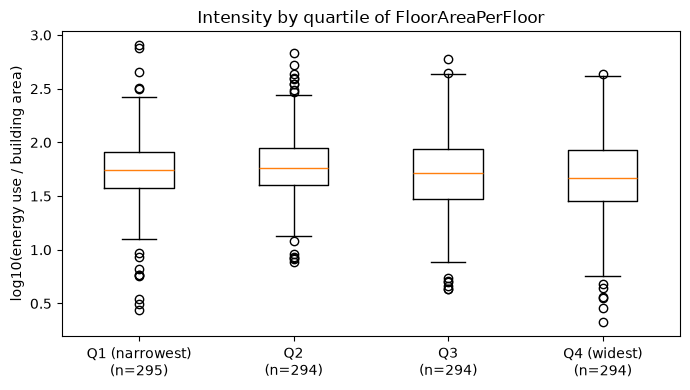

In [8]:
quartile = pd.qcut(
    train["FloorAreaPerFloor"],
    q=4,
    labels=["Q1 (narrowest)", "Q2", "Q3", "Q4 (widest)"],
)
groups = [train.loc[quartile == q, "log_intensity"] for q in quartile.cat.categories]

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(
    groups,
    tick_labels=[f"{q}\n(n={len(g)})" for q, g in zip(quartile.cat.categories, groups)],
)
ax.set_ylabel("log10(energy use / building area)")
ax.set_title("Intensity by quartile of FloorAreaPerFloor")
plt.tight_layout()
plt.show()

The median intensity is flat over the three narrowest quartiles and about 14% lower for the widest quartile. The spread inside each box is much larger than the differences between boxes. The signal is weak, as in notebook 2 (Spearman -0.08 here).

### Are the two weak signals only a property type effect?

Energy use per unit of area depends strongly on the property type, and the type is correlated with the parking and with the shape of the building. The table gives the Spearman correlation between each feature and the log10 intensity **inside each property type** (types with at least 30 training buildings).

In [9]:
def spearman(a, b):
    """Spearman correlation, NaN when a column is constant (undefined)."""
    return a.corr(b, method="spearman") if a.nunique() > 1 else np.nan


rows = {}
for ptype, d in train.groupby("PrimaryPropertyType"):
    if len(d) < 30:
        continue
    d_fapf = d.dropna(subset=["FloorAreaPerFloor"])
    rows[ptype] = {
        "n": len(d),
        "ParkingShare": spearman(d["ParkingShare"], d["log_intensity"]),
        "FloorAreaPerFloor": spearman(
            d_fapf["FloorAreaPerFloor"], d_fapf["log_intensity"]
        ),
    }
within_type = pd.DataFrame(rows).T.astype({"n": int})
within_type.round(2)

,n,ParkingShare,FloorAreaPerFloor
Distribution Center,49,0.10,0.16
Hotel,57,0.27,-0.06
K-12 School,37,NaN,-0.25
Large Office,131,0.14,-0.21
Medical Office,32,0.34,0.46
Mixed Use Property,80,0.26,-0.01
Other,197,0.21,0.00
Retail Store,73,-0.03,0.09
Small- and Mid-Sized Office,226,0.13,0.05
Warehouse,147,0.04,0.01


`ParkingShare` keeps a positive correlation with intensity inside most types (9 of the 10 types with a value, Retail Store is the exception). K-12 Schools have no variation in `ParkingShare` among the training schools, so no value. The signal is not a side effect of the property type, which supports keeping it.

`FloorAreaPerFloor`: The correlation is close to zero or inconsistent across types: no clear signal of its own.

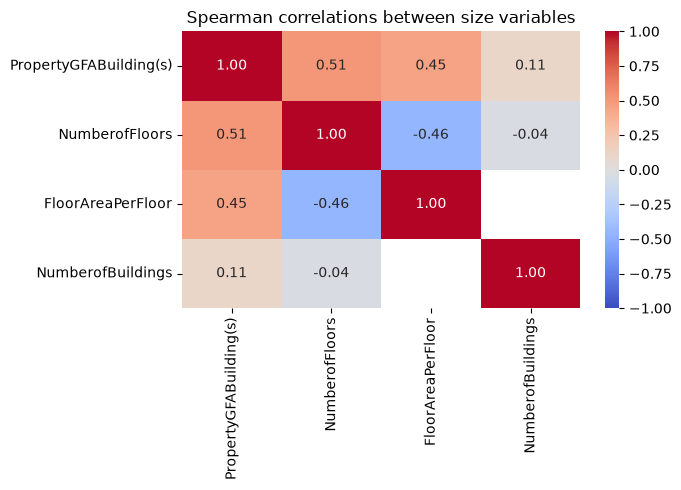

In [10]:
size_cols = [
    "PropertyGFABuilding(s)",
    "NumberofFloors",
    "FloorAreaPerFloor",
    "NumberofBuildings",
]

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(
    train[size_cols].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm",
    ax=ax,
)
ax.set_title("Spearman correlations between size variables")
plt.tight_layout()
plt.show()

### Redundancy among the size variables

- The size variables are moderately correlated (0.45 to 0.51), and `NumberofBuildings` is almost independent of them.
- By construction, area = floors × area per floor: any one of the three can be computed exactly from the other two. The linear model therefore gets only two of them. Tree-based models can keep all three, but their importance will have to be read together.
- `FloorAreaPerFloor` is missing for all campuses (hence the empty cell in the heatmap), so its missing values carry information: an indicator column will be added at imputation.

In [11]:
X_train.isna().sum()

PropertyGFABuilding(s)     0
PrimaryPropertyType        0
NumberofFloors            11
NumberofBuildings          0
Neighborhood               0
Latitude                   0
Longitude                  0
ParkingShare               0
HasMixedUsage              0
ConstructionPeriod         0
FloorAreaPerFloor         51
dtype: int64

## 3. Preprocessing

Two preprocessors, one per family of models. Both are `ColumnTransformer`s that will be the first step of a pipeline, so that imputation, scaling and encoding are fitted on the training folds only.

| | Linear models | Tree-based models |
|---|---|---|
| Skewed sizes (`PropertyGFABuilding(s)`, `NumberofFloors`, `NumberofBuildings`) | `log10` | as is (trees only use the order of the values) |
| Size variables | area + floors; `FloorAreaPerFloor` is dropped (area = floors × area per floor, a linear model cannot take all three) | all three |
| Missing values (`FloorAreaPerFloor`, `NumberofFloors`) | median + missing indicator | median + missing indicator |
| Scaling | `StandardScaler` on the numeric variables (needed for regularisation); binary variables and missing indicators are never scaled, to stay readable | none |
| Categories (`PrimaryPropertyType`, `Neighborhood`, `ConstructionPeriod`) | one-hot, unknown category ignored | one-hot, unknown category ignored |
| `ParkingShare`, `Latitude`, `Longitude` | scaled | as is |
| `HasMixedUsage` (binary) | as is | as is |

- The missing `FloorAreaPerFloor` values are mostly campuses (see section 2). The tree models keep the missing indicator for them. The linear model does not use this feature, so `NumberofBuildings` is its only campus signal. An indicator only exists for columns with missing values in the training data.
- No `min_frequency` in the one-hot encoding: the rare property types are the most extreme ones and must keep their own column.
- Which of the three size variables to drop for the linear model is a modeling choice: `FloorAreaPerFloor` is dropped because it has fewer imputed values (11 instead of 51), and floor area has no physical meaning for a campus.

In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

CATEGORICAL = ["PrimaryPropertyType", "Neighborhood", "ConstructionPeriod"]
LOG_COLS = ["PropertyGFABuilding(s)", "NumberofFloors", "NumberofBuildings"]
PLAIN_NUMERIC_COLS = [
    "ParkingShare",
    "Latitude",
    "Longitude",
]  # no log; scaled for the linear models only
BINARY_COLS = ["HasMixedUsage"]  # already 0/1, never scaled
TREE_ONLY_COLS = [
    "FloorAreaPerFloor"
]  # redundant with the two size variables for a linear model


def make_one_hot():
    return OneHotEncoder(handle_unknown="ignore", sparse_output=False)


def make_imputer(add_indicator):
    return SimpleImputer(strategy="median", add_indicator=add_indicator)


def make_linear_preprocessor():
    """Log of the skewed sizes, scaling, imputation, one-hot encoding.

    The missing indicator is generated by its own step, outside of the sub-pipeline,
    so that it is not scaled.
    """
    log_pipeline = make_pipeline(
        FunctionTransformer(np.log10, feature_names_out="one-to-one"),
        StandardScaler(),
        make_imputer(add_indicator=False),
    )
    return ColumnTransformer(
        [
            ("log", log_pipeline, LOG_COLS),
            ("missing", MissingIndicator(features="missing-only"), ["NumberofFloors"]),
            ("plain_numeric", StandardScaler(), PLAIN_NUMERIC_COLS),
            ("binary", "passthrough", BINARY_COLS),
            ("cat", make_one_hot(), CATEGORICAL),
        ],
        remainder="drop",  # FloorAreaPerFloor
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")


def make_tree_preprocessor():
    """No transformation of the values: imputation (with indicator) and one-hot encoding."""
    return ColumnTransformer(
        [
            ("num", make_imputer(add_indicator=True), LOG_COLS + TREE_ONLY_COLS),
            ("plain", "passthrough", PLAIN_NUMERIC_COLS + BINARY_COLS),
            ("cat", make_one_hot(), CATEGORICAL),
        ],
        verbose_feature_names_out=False,
    ).set_output(transform="pandas")

### Check

Each preprocessor is fitted on the training set and applied to both sets (only to check the output: during the modeling, the fit happens inside the cross-validation). The output must have no missing value, and the linear one must have centered numeric columns.

In [20]:
for name, make in [
    ("Linear", make_linear_preprocessor),
    ("Trees", make_tree_preprocessor),
]:
    prep = make().fit(X_train)
    out_train, out_test = prep.transform(X_train), prep.transform(X_test)
    assert not out_train.isna().any().any() and not out_test.isna().any().any()
    print(f"{name}: {X_train.shape[1]} -> {out_train.shape[1]} columns")
    indicators = [c for c in out_train.columns if c.startswith("missingindicator")]
    print(f"  missing indicators: {indicators}")

linear_out = make_linear_preprocessor().fit_transform(X_train)
linear_out.iloc[:, :6].astype(float).describe().loc[
    ["mean", "std", "min", "max"]
].round(2)

Linear: 11 -> 46 columns
  missing indicators: ['missingindicator_NumberofFloors']
Trees: 11 -> 48 columns
  missing indicators: ['missingindicator_NumberofFloors', 'missingindicator_FloorAreaPerFloor']


,PropertyGFABuilding(s),NumberofFloors,NumberofBuildings,missingindicator_NumberofFloors,ParkingShare,Latitude
mean,0.00,-0.00,-0.00,0.01,0.00,0.00
std,1.00,1.00,1.00,0.09,1.00,1.00
min,-1.82,-1.14,-0.17,0.00,-0.45,-2.26
max,3.77,3.90,11.81,1.00,5.10,2.48
